In [1]:
import time, json, warnings
import numpy as np, pandas as pd
from pathlib import Path
warnings.filterwarnings("ignore")
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, matthews_corrcoef, confusion_matrix)

P = Path("processed"); B = P / "balanced"
X_val = np.load(P / "X_val.npy"); y_val = np.load(P / "y_val.npy")

sets = ["none", "class_weight", "random_over", "random_under", "smote",
        "borderline_smote", "adasyn", "under_then_smote",
        "smote_tomek", "smote_enn", "tomek_links"]
K_LIST = [2, 20]

In [2]:
rows, cms = [], {}
for K in K_LIST:
    for s in sets:
        d = np.load(B / ("none.npz" if s == "class_weight" else f"{s}.npz"))
        X, y = d["X"].astype(np.float64), d["y"]       # float64 required by KMeans.predict

        sw = None                                       # class_weight: balanced sample weights
        if s == "class_weight":
            sw = np.where(y == 1, len(y) / (2 * (y == 1).sum()),
                                   len(y) / (2 * (y == 0).sum()))

        km = KMeans(n_clusters=K, n_init=5, random_state=42)
        t = time.time(); km.fit(X, sample_weight=sw); fit_s = time.time() - t

        # label each cluster by the (weighted) majority class of its training rows
        w = np.ones(len(y)) if sw is None else sw
        frac = np.zeros(K)                              # attack fraction per cluster
        for c in range(K):
            m = km.labels_ == c
            frac[c] = (w[m] * y[m]).sum() / w[m].sum() if m.any() else 0.5
        cluster_label = (frac >= 0.5).astype(int)

        vc = km.predict(X_val.astype(np.float64))
        pred, score = cluster_label[vc], frac[vc]
        tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
        cms[f"k{K}_{s}"] = [[int(tn), int(fp)], [int(fn), int(tp)]]
        rows.append({
            "k": K, "set": s, "train_rows": len(y),
            "accuracy": accuracy_score(y_val, pred),
            "precision": precision_score(y_val, pred, zero_division=0),
            "recall_attack": recall_score(y_val, pred),
            "normal_recall": tn / (tn + fp),
            "f1": f1_score(y_val, pred, zero_division=0),
            "macro_f1": f1_score(y_val, pred, average="macro"),
            "pr_auc": average_precision_score(y_val, score),
            "roc_auc": roc_auc_score(y_val, score),
            "mcc": matthews_corrcoef(y_val, pred),
            "FPR": fp / (fp + tn), "FNR": fn / (fn + tp),
            "attack_clusters": int(cluster_label.sum()), "fit_s": fit_s})
        print(K, s, "done")

results = pd.DataFrame(rows)

2 none done
2 class_weight done
2 random_over done
2 random_under done
2 smote done
2 borderline_smote done
2 adasyn done
2 under_then_smote done
2 smote_tomek done
2 smote_enn done
2 tomek_links done
20 none done
20 class_weight done
20 random_over done
20 random_under done
20 smote done
20 borderline_smote done
20 adasyn done
20 under_then_smote done
20 smote_tomek done
20 smote_enn done
20 tomek_links done


In [3]:
for K in K_LIST:
    print("=== K =", K)
    display(results[results.k == K].sort_values("mcc", ascending=False).round(4))

=== K = 2


,k,set,train_rows,accuracy,precision,recall_attack,normal_recall,f1,macro_f1,pr_auc,roc_auc,mcc,FPR,FNR,attack_clusters,fit_s
5,2,borderline_smote,242568,0.6575,0.9150,0.6656,0.6056,0.7706,0.5473,0.8980,0.6356,0.1922,0.3944,0.3344,1,1.0089
6,2,adasyn,242847,0.6577,0.9147,0.6661,0.6041,0.7709,0.5473,0.8979,0.6351,0.1916,0.3959,0.3339,1,0.9836
2,2,random_over,242568,0.6516,0.9156,0.6576,0.6134,0.7655,0.5443,0.8981,0.6355,0.1913,0.3866,0.3424,1,1.0480
1,2,class_weight,140311,0.6516,0.9156,0.6576,0.6134,0.7654,0.5443,0.8981,0.6355,0.1913,0.3866,0.3424,1,0.7640
8,2,smote_tomek,242092,0.6516,0.9156,0.6576,0.6134,0.7654,0.5443,0.8980,0.6355,0.1912,0.3866,0.3424,1,1.1502
4,2,smote,242568,0.6516,0.9156,0.6576,0.6134,0.7654,0.5443,0.8980,0.6355,0.1912,0.3866,0.3424,1,1.0457
7,2,under_then_smote,76108,0.6516,0.9156,0.6576,0.6134,0.7654,0.5443,0.8980,0.6355,0.1912,0.3866,0.3424,1,0.3251
3,2,random_under,38054,0.6515,0.9156,0.6575,0.6134,0.7654,0.5442,0.8980,0.6355,0.1912,0.3866,0.3425,1,0.1527
9,2,smote_enn,236452,0.6515,0.9152,0.6578,0.6115,0.7655,0.5440,0.8978,0.6347,0.1901,0.3885,0.3422,1,1.0118
0,2,none,140311,0.8644,0.8644,1.0000,0.0000,0.9273,0.4636,0.8986,0.6376,0.0000,1.0000,0.0000,2,0.6677


=== K = 20


,k,set,train_rows,accuracy,precision,recall_attack,normal_recall,f1,macro_f1,pr_auc,roc_auc,mcc,FPR,FNR,attack_clusters,fit_s
18,20,under_then_smote,76108,0.8370,0.9622,0.8446,0.7886,0.8996,0.7335,0.9820,0.9062,0.5066,0.2114,0.1554,12,1.6402
13,20,random_over,242568,0.8270,0.9611,0.8335,0.7851,0.8928,0.7222,0.9820,0.9073,0.4889,0.2149,0.1665,12,4.3667
20,20,smote_enn,236452,0.8236,0.9610,0.8296,0.7854,0.8905,0.7188,0.9803,0.9009,0.4838,0.2146,0.1704,12,4.8023
15,20,smote,242568,0.8232,0.9609,0.8291,0.7851,0.8902,0.7182,0.9812,0.9054,0.4830,0.2149,0.1709,11,4.1824
19,20,smote_tomek,242092,0.8188,0.9629,0.8221,0.7981,0.8869,0.7157,0.9810,0.9036,0.4829,0.2019,0.1779,11,4.3414
12,20,class_weight,140311,0.7920,0.9706,0.7831,0.8487,0.8668,0.6961,0.9819,0.9083,0.4709,0.1513,0.2169,10,2.5103
14,20,random_under,38054,0.8014,0.9590,0.8046,0.7810,0.8751,0.6956,0.9782,0.8892,0.4491,0.2190,0.1954,12,0.8275
21,20,tomek_links,140193,0.8934,0.8944,0.9940,0.2521,0.9416,0.6661,0.9811,0.9043,0.4330,0.7479,0.0060,19,3.4683
11,20,none,140311,0.8933,0.8944,0.9939,0.2519,0.9415,0.6659,0.9814,0.9046,0.4323,0.7481,0.0061,19,3.0175
17,20,adasyn,242847,0.6852,0.9880,0.6437,0.9500,0.7795,0.6148,0.9685,0.8283,0.4098,0.0500,0.3563,8,4.7175


In [4]:
results.round(4).to_csv(P / "kmeans_results.csv", index=False)
json.dump(cms, open(P / "kmeans_confusion.json", "w"))

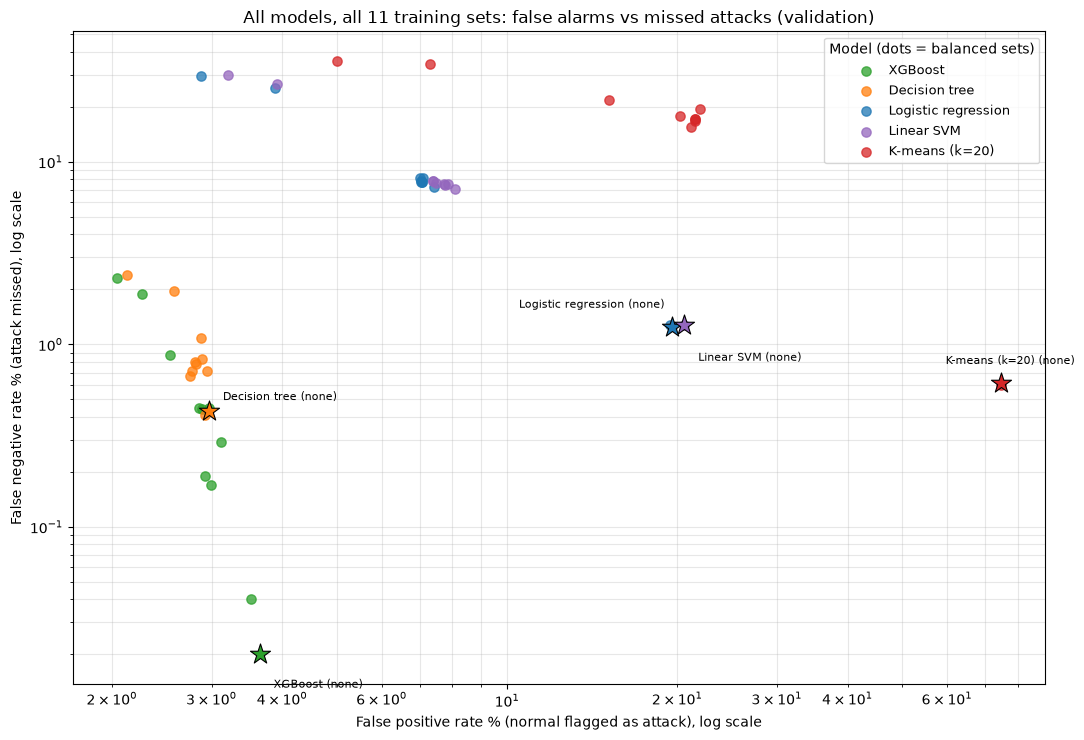

In [5]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

P = Path("processed")
lr = pd.read_csv(P / "lr_results.csv");  sv = pd.read_csv(P / "svm_results.csv")
xg = pd.read_csv(P / "xgb_results.csv"); dt = pd.read_csv(P / "dt_results.csv")
km = pd.read_csv(P / "kmeans_results.csv"); km = km[km["k"] == 20]

models = {"XGBoost": (xg, "tab:green"), "Decision tree": (dt, "tab:orange"),
          "Logistic regression": (lr, "tab:blue"), "Linear SVM": (sv, "tab:purple"),
          "K-means (k=20)": (km, "tab:red")}
label_off = {"Logistic regression": (-110, 14), "Linear SVM": (10, -26),
             "XGBoost": (10, -24), "Decision tree": (10, 8), "K-means (k=20)": (-40, 14)}

fig, ax = plt.subplots(figsize=(11, 7.5))
for name, (d, c) in models.items():
    bal = d[d["set"] != "none"]; none = d[d["set"] == "none"]
    ax.scatter(bal["FPR"] * 100, bal["FNR"] * 100, s=45, color=c, alpha=.75, label=name, zorder=3)
    ax.scatter(none["FPR"] * 100, none["FNR"] * 100, s=230, marker="*", color=c,
               edgecolor="black", linewidth=.8, zorder=4)
    for _, x in none.iterrows():
        ax.annotate(f"{name} (none)", (x["FPR"] * 100, x["FNR"] * 100),
                    xytext=label_off[name], textcoords="offset points", fontsize=8)

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("False positive rate % (normal flagged as attack), log scale")
ax.set_ylabel("False negative rate % (attack missed), log scale")
ax.set_title("All models, all 11 training sets: false alarms vs missed attacks (validation)")
ax.grid(alpha=.3, which="both")
ax.legend(title="Model (dots = balanced sets)", loc="upper right", fontsize=9)
plt.tight_layout(); plt.savefig(P / "all_models_tradeoff.png", dpi=150); plt.show()